# Same-week links: does awareness move consideration within the week?

**Audience:** analysts who have read the practitioner guide (01).

**The question.** Awareness jumps this week after a TV burst. Does consideration jump with it in the same week, or only from next week? The answer says how fast a campaign reaches the bottom of the funnel. It is also the one link a standard VECM cannot estimate:

- `Gamma` covers last week's growth, not this week's.
- `B` covers the drivers, not the brand metrics.
- A GIRF or a Cholesky IRF assumes the same-week structure instead of estimating it.

This notebook builds up the answer in five steps:

1. Why a regression finds a link that is not there.
2. The fix: a driver that moves awareness but not consideration.
3. The test before fitting: `granger_pretest(contemporaneous=..., excluded=...)`.
4. The link in the model: `BayesianVECM(contemporaneous=..., excluded=...)`.
5. When it goes wrong, from 110 simulated data sets with a known answer.

In [1]:
# Sampling configuration, as in the other guides.
FAST_SAMPLING = True

if FAST_SAMPLING:
    DRAWS, TUNE, CHAINS = 1000, 1000, 2
else:
    DRAWS, TUNE, CHAINS = 2000, 1000, 4

LEVEL = 0.90  # every interval in this notebook is a 90% interval
TAILS = (100 * (1 - LEVEL) / 2, 100 * (1 + LEVEL) / 2)

In [2]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsmodels.tsa.vector_ar.vecm import VECM

from bayesian_vecm import BayesianVECM, granger_pretest, simulate_brand_data

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 120)
OLS_COLOUR, IV_COLOUR, BAYES_COLOUR = "#eb6834", "#1baf7a", "#2a78d6"
SPEC = {"k_ar_diff": 1, "coint_rank": 2, "deterministic": "co"}
SALES, AWARE, CONS = "organic_sales", "brand_awareness", "brand_consideration"
CHANNELS = ["brand_spend", "pr_reach", "sponsorship_reach"]
MACRO = ["interest_rate", "consumer_confidence"]
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

## 1. The data

Two versions of the default simulated brand, 260 weeks each, from the same random draws:

- **No link:** awareness moves consideration only from the following week (`Gamma` 0.25), as in the other guides.
- **Link 0.2:** the same, plus a same-week link. 1% more awareness growth adds 0.2% to consideration growth in the same week.

In both, the channels act on awareness only. Interest rate and consumer confidence act on consideration only.

In [3]:
LINK = 0.2
no_link = simulate_brand_data()
linked = simulate_brand_data(contemporaneous={CONS: {AWARE: LINK}})
print("Same-week links in the truth (row = effect, column = cause):")
print(pd.DataFrame(linked.truth.links, index=linked.endog.columns, columns=linked.endog.columns))

Same-week links in the truth (row = effect, column = cause):
                     organic_sales  brand_awareness  brand_consideration
organic_sales                  0.0              0.0                  0.0
brand_awareness                0.0              0.0                  0.0
brand_consideration            0.0              0.2                  0.0


## 2. Why a regression finds a link that is not there

The obvious approach regresses consideration growth on awareness growth in the same week, with the usual VECM controls: last week's levels and growth, the constant and the drivers that act on consideration.

The trouble is that the brand metrics share shocks. A news story or a competitor's launch moves awareness and consideration in the same week. In the simulator this is a shock to the common trend that all three series load on. The regression cannot tell that shared movement from a link.

In [4]:
def controls(endog, exog):
    # Constant, last week's levels and growth, and the drivers that act on consideration.
    dy = endog.diff()
    x = pd.concat(
        [endog.shift(1).add_suffix(" level"), dy.shift(1).add_suffix(" growth"), exog[MACRO]],
        axis=1,
    ).assign(const=1.0)
    keep = x.notna().all(axis=1) & dy.notna().all(axis=1)
    return dy[keep], x[keep], exog[keep]


def ols(y, x):
    return np.linalg.lstsq(x.to_numpy(), y.to_numpy(), rcond=None)[0]


for label, data in [("No link", no_link), (f"Link {LINK}", linked)]:
    dy, x, ex = controls(data.endog, data.exog)
    coef = ols(dy[CONS], pd.concat([dy[AWARE], x], axis=1))[0]
    print(f"{label:<9} regression estimate of the link: {coef:.2f}")

No link   regression estimate of the link: 0.31
Link 0.2  regression estimate of the link: 0.40


READING_OLS

One data set could be unlucky. `tools/same_week_pretest_check.py` ran the same comparison on 200 simulated data sets with each truth. The orange bars below are the regression, the green bars the fix from section 3:

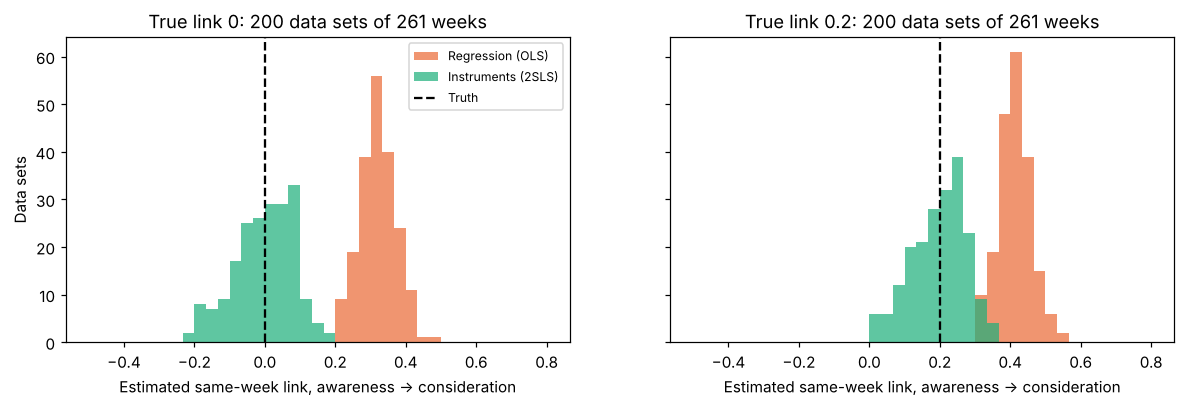

,"regression, mean","instruments, mean"
truth,,
0.0,0.32,-0.0
0.2,0.41,0.2


In [5]:
pretest_runs = pd.read_csv(ROOT / "tools" / "same_week_pretest_check_results.csv")
weekly = pretest_runs[
    (pretest_runs.freq == "weekly") & (pretest_runs.cause == AWARE) & (pretest_runs.effect == CONS)
]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
bins = np.linspace(-0.5, 0.8, 40)
for ax, (truth_value, group) in zip(axes, weekly.groupby("truth"), strict=True):
    ax.hist(group.ols, bins=bins, color=OLS_COLOUR, alpha=0.7, label="Regression (OLS)")
    ax.hist(group.estimate, bins=bins, color=IV_COLOUR, alpha=0.7, label="Instruments (2SLS)")
    ax.axvline(truth_value, color="black", ls="--", label="Truth")
    ax.set_title(f"True link {truth_value:g}: 200 data sets of 261 weeks")
    ax.set_xlabel("Estimated same-week link, awareness -> consideration")
axes[0].set_ylabel("Data sets")
axes[0].legend(fontsize=8)
plt.show()
summary = weekly.groupby("truth")[["ols", "estimate"]].mean().round(2)
summary.columns = ["regression, mean", "instruments, mean"]
summary

## 3. The fix: a driver that moves awareness but not consideration

Suppose brand spend acts on awareness and reaches consideration **only through awareness**. Then:

- Brand spend's effect on awareness growth is `b`.
- Its effect on consideration growth in the same week is `link × b`. There is no other path.
- So `link = (effect on consideration) / (effect on awareness)`.

The shared shocks drop out, because brand spend does not respond to them. This is the instrumental variables idea, with brand spend as the **instrument**. The assumption that brand spend has no direct effect on consideration is the **exclusion**.

Each of the three channels gives its own estimate of the link. The cell below computes them by hand: regress each brand metric's growth on the channels and the controls, then divide.

In [6]:
rows = []
for label, data in [("No link", no_link), (f"Link {LINK}", linked)]:
    dy, x, ex = controls(data.endog, data.exog)
    design = pd.concat([ex[CHANNELS], x], axis=1)
    on_aware = ols(dy[AWARE], design)[: len(CHANNELS)]
    on_cons = ols(dy[CONS], design)[: len(CHANNELS)]
    for ch, a, c in zip(CHANNELS, on_aware, on_cons, strict=True):
        rows.append(
            {
                "data": label,
                "channel": ch,
                "effect on awareness": a,
                "effect on consideration": c,
                "ratio = link": c / a,
            }
        )
pd.DataFrame(rows).set_index(["data", "channel"]).round(4)

effect on awareness  effect on consideration  ratio = link
data     channel                                                                      
No link  brand_spend                     0.0165                  -0.0045       -0.2712
         pr_reach                        0.0134                   0.0028        0.2063
         sponsorship_reach               0.0057                   0.0009        0.1625
Link 0.2 brand_spend                     0.0166                  -0.0008       -0.0501
         pr_reach                        0.0134                   0.0051        0.3827
         sponsorship_reach               0.0057                   0.0021        0.3707

READING_RATIOS

## 4. The test before fitting

`granger_pretest` runs two-stage least squares (2SLS) with the same controls. Two arguments describe the assumption:

- `contemporaneous`: each effect and its possible same-week causes.
- `excluded`: for each effect, the drivers that act on it only through the causes. These are the instruments.

In [7]:
LINKS = {CONS: [AWARE]}
EXCLUDED = {CONS: CHANNELS}

cols = ["cause", "effect", "ols", "estimate", "std_err", "first_stage_f", "sargan_p", "verdict"]
tables = []
for label, data in [("No link", no_link), (f"Link {LINK}", linked)]:
    result = granger_pretest(data.endog, data.exog, contemporaneous=LINKS, excluded=EXCLUDED)
    tables.append(result.same_week[cols].assign(data=label))
pd.concat(tables).set_index("data").round(3)

,cause,effect,ols,estimate,std_err,first_stage_f,sargan_p,verdict
data,,,,,,,,
No link,brand_awareness,brand_consideration,0.359,0.018,0.083,63.509,0.270,no clear evidence
Link 0.2,brand_awareness,brand_consideration,0.451,0.224,0.076,63.774,0.258,same-week link


How to read each column:

- `ols` is the regression from section 2 and `estimate` is 2SLS.
- `first_stage_f` asks whether the channels move awareness enough to be useful. Below 10 the instruments are **weak** and 2SLS drifts back towards the regression. The verdict then says "weak instruments".
- `sargan_p` asks whether the channels agree on the link. A small value means at least one exclusion is wrong. The verdict then says "instruments disagree".

READING_PRETEST

## 5. The link in the model

The same two arguments go into `BayesianVECM`. The model becomes

```
A0 Δy_t = α β' y_{t-1} + Γ Δy_{t-1} + B_s X_t + u_t
```

where `A0` has ones on the diagonal and minus each link off it. `B_s` holds the **direct** effects of the drivers, with zeros where `excluded` says so. The shocks `u_t` keep a full covariance, so the shared shocks stay shocks and do not leak into the link.

In practice the model is the usual VECM with one restriction: the same-week driver effects `B` must equal `A0⁻¹ B_s`. That is the ratio argument of section 3, applied inside the full system. The link gets a `Normal(0, 0.5)` prior.

In [8]:
model = BayesianVECM(**SPEC, contemporaneous=LINKS, excluded=EXCLUDED).fit(
    linked.endog,
    exog=linked.exog,
    draws=DRAWS,
    tune=TUNE,
    chains=CHAINS,
    target_accept=0.95,
    random_seed=14,
    progressbar=False,
)
summary = model.summary().apply(pd.to_numeric, errors="coerce")
print(f"Divergences:   {int(model.idata_.sample_stats['diverging'].sum())}")
print(f"Max r-hat:     {summary['r_hat'].max():.3f}")
print(f"Min bulk ESS:  {summary['ess_bulk'].min():.0f}")
model.same_week_links().assign(truth=LINK).round(3)

NUTS[nutpie]: [alpha, beta_free, Gamma_centred, Sigma_chol, A0_links, B_raw]


Divergences:   0
Max r-hat:     1.003
Min bulk ESS:  662


,cause,effect,mean,lower,upper,evidence,link,truth
0,brand_awareness,brand_consideration,0.173,0.058,0.281,0.988,True,0.2


READING_MODEL

**Direct and via the link.** With the link in place, brand spend's same-week effect on consideration splits in two. The direct part is zero by assumption. The rest arrives through awareness. `statsmodels` estimates the same total but cannot split it, so a reader would take it for a direct effect:

In [9]:
names, drivers = list(linked.endog.columns), list(linked.exog.columns)
cons, aware, j = names.index(CONS), names.index(AWARE), drivers.index("brand_spend")
post = model.idata_.posterior


def draws(name):
    values = post[name].values
    return values.reshape(-1, *values.shape[2:])


def interval(x):
    lo, hi = np.percentile(x, TAILS)
    return f"{np.mean(x):.4f} ({lo:.4f} to {hi:.4f})"


sm = VECM(linked.endog, exog=linked.exog, **SPEC).fit()
link_draws = draws("A0_links")[:, 0]
via_link = link_draws * draws("B_structural")[:, aware, j]
pd.DataFrame(
    {
        "truth": [linked.truth.b[cons, j], 0.0, linked.truth.b[cons, j]],
        "statsmodels": [sm.det_coef[cons, 1 + j], np.nan, np.nan],
        "BayesianVECM": [
            interval(draws("B")[:, cons, j]),
            "0 (excluded)",
            interval(via_link),
        ],
    },
    index=["total same-week effect", "direct", "via awareness"],
)

,truth,statsmodels,BayesianVECM
total same-week effect,0.0036,-0.000658,0.0032 (0.0009 to 0.0054)
direct,0.0000,NaN,0 (excluded)
via awareness,0.0036,NaN,0.0032 (0.0009 to 0.0054)


**What the link does not change.**

- `exog_irf()`, forecasts and the return per channel use the total effects `B`. They are the same as without the link, up to sampling noise.
- Impulse responses to a **shock** still need GIRF or a Cholesky ordering. The links are identified by the drivers, not by the shocks, so they say nothing about how the shared shocks split.

## 6. When it goes wrong

One data set says little about a method. `tools/same_week_check.py` fitted the model on 110 simulated data sets in six settings:

| Setting | Data | Truth |
|---|---|---|
| weekly link 0 | 260 weeks, 20 data sets | no link |
| weekly link 0.2 | 260 weeks, 20 data sets | link 0.2 |
| monthly link 0, monthly link 0.2 | the same weeks summed or averaged into 60 months | the same-month ratio implied by the weekly parameters |
| wrong exclusion | 260 weeks, 10 data sets, link 0.2 | brand spend also acts on consideration directly, at a third of its effect on awareness |
| weak | 60 months, 20 data sets, no weekly link | consideration and awareness -> sales, with all five drivers as instruments |

Each row below gives the truth, the posterior mean and 2SLS averaged over data sets. `coverage` is the share of 90% intervals that contain the truth. `found` is the share with evidence of at least 0.95 that the link is not zero.

In [10]:
runs = pd.read_csv(ROOT / "tools" / "same_week_check_results.csv")
links_only = runs[(runs.fit == "links") & runs.quantity.str.startswith("link")]
table = links_only.groupby(["setting", "quantity"], sort=False).agg(
    truth=("truth", "mean"),
    posterior=("mean", "mean"),
    two_sls=("two_sls", "mean"),
    coverage=("covered", "mean"),
    found=("evidence", lambda e: (e >= 0.95).mean()),
    first_stage_f=("first_stage_f", "mean"),
    sargan_rejects=("sargan_p", lambda p: (p < 0.05).mean()),
    divergences=("diverging", "sum"),
)
table.round(2)

,,truth,posterior,two_sls,coverage,found,first_stage_f,sargan_rejects,divergences
setting,quantity,,,,,,,,
weekly link 0,link: brand_awareness -> brand_consideration,0.0,-0.04,-0.05,0.85,0.15,66.38,0.15,0


READING_VALIDATION

## 7. With your own data

**Choosing the exclusions.** This is the step that matters, and the data cannot fully check it.

- **The instrument must move the cause.** Check `first_stage_f` in the pretest. Below 10 the link is not worth reading.
- **It must reach the effect only through the cause.** A brand TV campaign that builds awareness is a plausible instrument for awareness -> consideration. A campaign with a price message that sells the product directly is not. Sargan flags exclusions that disagree with each other, but if every instrument breaks the exclusion in the same way it cannot.
- **It must not react to this week's shocks.** Spend planned months ahead is fine. Spend raised because consideration dipped this week is not.

**Weekly or monthly.** A weekly link and a monthly link are different quantities. On monthly data the same-month link also holds the lagged weekly effects that land inside the month. Prefer weekly data when the question is how fast the funnel moves.

**The order of work.**

1. `granger_pretest(endog, exog, contemporaneous=links, excluded=excluded)`. Read the verdict, the first-stage F and Sargan.
2. If the verdict is "same-week link" or "no clear evidence", fit `BayesianVECM(..., contemporaneous=links, excluded=excluded)` and read `same_week_links()`.
3. If it says "weak instruments" or "instruments disagree", leave the link out and report the same-period correlation instead.